# BIL545 – Proje 1 (Vize)
## COMPAS Yeniden Suç İşleme Risk Skorlarının İncelenmesi
**Öğrenci:** Murat Sağlam  
**Öğrenci No:** 264327008  
**Konu:** 9.16 – Yeniden suç işleme risk skorları (COMPAS)  
**Veri:** ProPublica COMPAS – `compas-scores-two-years.csv`

> **Akademik ve etik sınır:** `two_year_recid`, gerçek suç işleme olgusunu değil, iki yıl içinde yeniden tutuklanma kaydını temsil eden bir vekil değişkendir. Bu çalışma bireyler hakkında karar vermek, risk puanı üretmek veya ceza adaleti kararlarını desteklemek için tasarlanmamıştır. Sonuçlar yalnızca tarihsel veri setinin yöntemsel/adillik denetimidir.

## Çalışma notu – teslimden önce
- Bu defter bir çalışma şablonudur; hücreleri Google Colab'da **Çalışma Zamanı → Tümünü çalıştır** ile çalıştırın.
- Çıktılar çalıştırılmadan sonuç, skor veya yorum yazmayın.
- Her kod bölümünden sonra kendi bulgularınızı açıklayan bir **Yorum** hücresi ekleyin.
- ProPublica deposunda veri için açık bir lisans beyanı görünmediğinden veri dosyasını GitHub'a yüklemeyin. Öğretim üyesinden yeniden kullanım/yeniden dağıtım koşulunu teyit edin.
- Kişisel tanımlayıcı alanlar model girdisi yapılmaz ve temiz veri dışa aktarımına alınmaz.

## 1. Grup bilgisi ve araştırma sorusu
Tek kişilik çalışma. Araştırma sorusu: **COMPAS risk skorlarının ve bu veri üzerinden kurulan sınıflandırma modellerinin hata oranları ırk ve cinsiyet grupları arasında eşit midir?**

In [ ]:
!pip -q install -U scikit-learn pandas numpy scipy matplotlib seaborn mlxtend statsmodels

ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
google-colab 1.0.0 requires pandas==2.2.3, but you have pandas 3.1.0 which is incompatible.
numba 0.64.0 requires numpy<2.5,>=1.22, but you have numpy 2.5.4 which is incompatible.


In [ ]:
import sys, platform, warnings, random, time, json, os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn import __version__ as sklearn_version
from sklearn.model_selection import (train_test_split, RepeatedStratifiedKFold,
    StratifiedKFold, cross_validate, cross_val_score, GridSearchCV)
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler, TargetEncoder
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier, export_text
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.metrics import (balanced_accuracy_score, f1_score, roc_auc_score,
    confusion_matrix, classification_report, ConfusionMatrixDisplay)
from scipy.stats import chi2
from statsmodels.stats.contingency_tables import mcnemar
from mlxtend.frequent_patterns import apriori, fpgrowth, association_rules
from mlxtend.preprocessing import TransactionEncoder
from IPython.display import display
SEED = 264327008
np.random.seed(SEED); random.seed(SEED)
print("Python:", sys.version)
print("Platform:", platform.platform())
print("scikit-learn:", sklearn_version)
print("Seed:", SEED)

/usr/local/lib/python3.13/dist-packages/pandas/core/arrays/masked.py:63: UserWarning: Pandas requires version '1.5.0' or newer of 'bottleneck' (version '1.4.2' currently installed).
  from pandas.core import (


Python: 3.13.18 (main, Oct 26 2026, 15:28:15) [GCC 13.3.0]
Platform: Linux-6.6.159+-x86_64-with-glibc2.39
scikit-learn: 1.9.1
Seed: 264327008


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


## 2. Veri yükleme ve veri künyesi
Kaynak: ProPublica'nın yayımladığı COMPAS analiz deposu. Ham dosya 7.214 satırdır. ProPublica'nın standart analitik filtresi uygulandığında 6.172 satır beklenir; gerçek sayı aşağıda kodla doğrulanır.

In [ ]:
DATA_URL = "https://raw.githubusercontent.com/propublica/compas-analysis/master/compas-scores-two-years.csv"
raw = pd.read_csv(DATA_URL)
print("Ham boyut:", raw.shape)
display(raw.head())
print("Sütunlar:", raw.columns.tolist())

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

Ham boyut: (7214, 53)


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


,id,name,first,last,compas_screening_date,sex,dob,age,age_cat,race,...,v_decile_score,v_score_text,v_screening_date,in_custody,out_custody,priors_count.1,start,end,event,two_year_recid
0,1,miguel hernandez,miguel,hernandez,2013-08-14,Male,1947-04-18,69,Greater than 45,Other,...,1,Low,2013-08-14,2014-07-07,2014-07-14,0,0,327,0,0
1,3,kevon dixon,kevon,dixon,2013-01-27,Male,1982-01-22,34,25 - 45,African-American,...,1,Low,2013-01-27,2013-01-26,2013-02-05,0,9,159,1,1
2,4,ed philo,ed,philo,2013-04-14,Male,1991-05-14,24,Less than 25,African-American,...,3,Low,2013-04-14,2013-06-16,2013-06-16,4,0,63,0,1
3,5,marcu brown,marcu,brown,2013-01-13,Male,1993-01-21,23,Less than 25,African-American,...,6,Medium,2013-01-13,NaN,NaN,1,0,1174,0,0
4,6,bouthy pierrelouis,bouthy,pierrelouis,2013-03-26,Male,1973-01-22,43,25 - 45,Other,...,1,Low,2013-03-26,NaN,NaN,2,0,1102,0,0


Sütunlar: ['id', 'name', 'first', 'last', 'compas_screening_date', 'sex', 'dob', 'age', 'age_cat', 'race', 'juv_fel_count', 'decile_score', 'juv_misd_count', 'juv_other_count', 'priors_count', 'days_b_screening_arrest', 'c_jail_in', 'c_jail_out', 'c_case_number', 'c_offense_date', 'c_arrest_date', 'c_days_from_compas', 'c_charge_degree', 'c_charge_desc', 'is_recid', 'r_case_number', 'r_charge_degree', 'r_days_from_arrest', 'r_offense_date', 'r_charge_desc', 'r_jail_in', 'r_jail_out', 'violent_recid', 'is_violent_recid', 'vr_case_number', 'vr_charge_degree', 'vr_offense_date', 'vr_charge_desc', 'type_of_assessment', 'decile_score.1', 'score_text', 'screening_date', 'v_type_of_assessment', 'v_decile_score', 'v_score_text', 'v_screening_date', 'in_custody', 'out_custody', 'priors_count.1', 'start', 'end', 'event', 'two_year_recid']


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

In [ ]:
# ProPublica'nın yaygın kullanılan standart filtreleri:
required = ["days_b_screening_arrest", "is_recid", "c_charge_degree", "score_text"]
missing_required = [c for c in required if c not in raw.columns]
assert not missing_required, f"Eksik zorunlu sütunlar: {missing_required}"

df = raw.loc[
    raw["days_b_screening_arrest"].between(-30, 30)
    & (raw["is_recid"] != -1)
    & (raw["c_charge_degree"] != "O")
    & (raw["score_text"] != "N/A")
].copy()

print("Filtre sonrası boyut:", df.shape)
print("Beklenen standart gözlem sayısı: 6172; gözlenen:", len(df))

Filtre sonrası boyut: (6172, 53)
Beklenen standart gözlem sayısı: 6172; gözlenen: 6172


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

### Veri künyesi – kaynakta desteklenen bilgiler
ProPublica, Broward County, Florida'da 2013 ve 2014 yıllarında COMPAS puanı verilen kişilerle ilgili kamu kayıtlarını incelemiştir. COMPAS puanları 1–10 aralığındadır; 1–4 düşük, 5–7 orta, 8–10 yüksek risk kategorisidir. ProPublica'nın hedefi iki yıllık takipte yeni tutuklanma kaydıdır.

**Sınırlılıklar:** Hedef suçun kendisi değildir; tutuklanma ve kayıt süreçlerinden etkilenir. Veri belirli bir ilçe, dönem ve kamu kayıtlarıyla sınırlıdır. Örneklem tüm nüfusu temsil etmez. Kaynağın açık veri lisansı ayrıca teyit edilmelidir.

## 3. Keşifsel veri analizi (EDA)

In [ ]:
print("Boyut:", df.shape)
print("\nHedef dağılımı:")
display(df["two_year_recid"].value_counts(dropna=False).rename("adet").to_frame())
display((df["two_year_recid"].value_counts(normalize=True)*100).rename("yüzde").to_frame())
print("Yinelenen satır:", df.duplicated().sum())

Boyut: (6172, 53)

Hedef dağılımı:


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

,adet
two_year_recid,
0,3363
1,2809


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


,yüzde
two_year_recid,
0,54.48801
1,45.51199


Yinelenen satır: 0


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

In [ ]:
# Sütun profili: tip, eksik oranı, farklı değer ve sıfır oranı
profile = pd.DataFrame({
    "dtype": df.dtypes.astype(str),
    "missing_count": df.isna().sum(),
    "missing_pct": df.isna().mean()*100,
    "n_unique": df.nunique(dropna=True),
    "zero_pct": [(df[c].eq(0).mean()*100 if pd.api.types.is_numeric_dtype(df[c]) else np.nan) for c in df.columns]
}).sort_values("missing_pct", ascending=False)
display(profile)

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

,dtype,missing_count,missing_pct,n_unique,zero_pct
violent_recid,float64,6172,100.000000,0,0.000000
vr_charge_degree,str,5480,88.788075,9,NaN
vr_offense_date,str,5480,88.788075,504,NaN
vr_case_number,str,5480,88.788075,692,NaN
vr_charge_desc,str,5480,88.788075,81,NaN
c_arrest_date,str,5388,87.297472,416,NaN
r_jail_in,str,4175,67.644200,923,NaN
r_days_from_arrest,float64,4175,67.644200,177,23.525599
r_jail_out,str,4175,67.644200,892,NaN
r_charge_desc,str,3228,52.300713,318,NaN


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

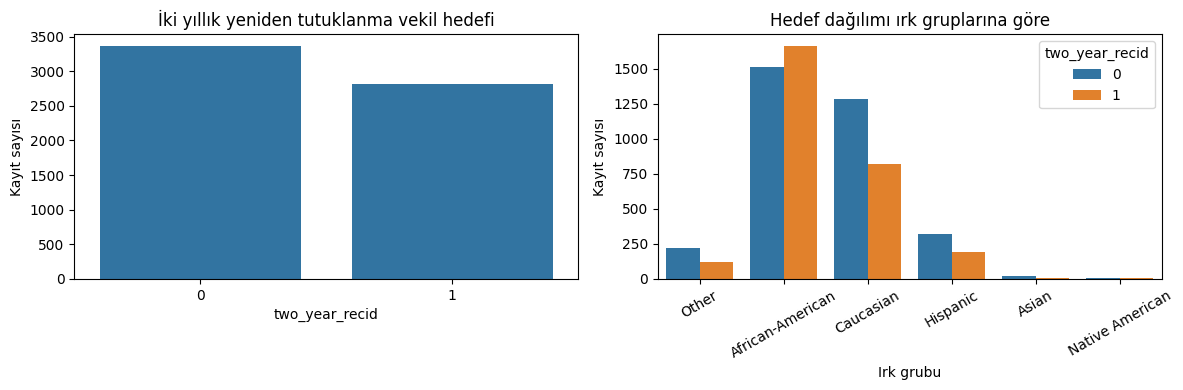

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(12,4))
sns.countplot(data=df, x="two_year_recid", ax=axes[0])
axes[0].set(title="İki yıllık yeniden tutuklanma vekil hedefi", xlabel="two_year_recid", ylabel="Kayıt sayısı")
sns.countplot(data=df, x="race", hue="two_year_recid", ax=axes[1])
axes[1].set(title="Hedef dağılımı ırk gruplarına göre", xlabel="Irk grubu", ylabel="Kayıt sayısı")
axes[1].tick_params(axis="x", rotation=30)
plt.tight_layout()

### Yorum – EDA
Bu hücreyi çalıştırdıktan sonra hedef dengesini, grup büyüklüklerini, eksik verileri ve olası temsil sorunlarını gerçek çıktılara dayanarak yazın. Nedensel sonuç çıkarmayın.

## 4. Eksiklik analizi ve karar gerekçesi

In [ ]:
# Eksiklik desenleri
missing_cols = profile.query("missing_count > 0").index.tolist()
print("Eksik içeren sütunlar:", missing_cols)
if missing_cols:
    display(df[missing_cols].isna().astype(int).value_counts().head(15).to_frame("pattern_count"))
top2_missing = profile.query("missing_count > 0").head(2).index.tolist()
print("En çok eksik iki sütun:", top2_missing)

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

Eksik içeren sütunlar: ['violent_recid', 'vr_charge_degree', 'vr_offense_date', 'vr_case_number', 'vr_charge_desc', 'c_arrest_date', 'r_jail_in', 'r_days_from_arrest', 'r_jail_out', 'r_charge_desc', 'r_case_number', 'r_charge_degree', 'r_offense_date', 'c_offense_date', 'c_charge_desc']


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


pattern_count
violent_recid vr_charge_degree vr_offense_date vr_case_number vr_charge_desc c_arrest_date r_jail_in r_days_from_arrest r_jail_out r_charge_desc r_case_number r_charge_degree r_offense_date c_offense_date c_charge_desc               
1             1                1               1              1              1             1         1                  1          1             1             1               1              0              0                       2775
                                                                                           0         0                  0          0             0             0               0              0              0                       1274
                                                                                           1         1                  1          0             0             0               0              0              0                        702
              0                0               0              0              1             0         0                  0          0             0             0               0              0              0                        437
              1                1               1              1              0             1         1                  1          1             1             1               1              1              0                        402
                                                                                           0         0                  0          0             0             0               0              1              0                        178
              0                0               0              0              1             1         1                  1          0             0             0               0              0              0                        157
              1                1               1              1              0             1         1                  1          0             0             0               0              1              0                         99
              0                0               0              0              0             0         0                  0          0             0             0               0              1              0                         70
              1                1               1              1              1             0         0                  0          1             0             0               0              0              0                         33
              0                0               0              0              0             1         1                  1          0             0             0               0              1              0                         27
              1                1               1              1              1             1         1                  1          1             1             1               1              0              1                          5
                                                                             0             0         0                  0          1             0             0               0              1              0                          4
                                                                             1             1         1                  1          1             0             0               0              0              0                          4
                                                                             0             1         1                  1          1             0             0               0              1              0                          4

En çok eksik iki sütun: ['violent_recid', 'vr_charge_degree']


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

**MCAR/MAR/MNAR değerlendirmesi:** İstatistiksel test tek başına mekanizmayı kesin olarak kanıtlamaz. En çok eksik iki sütun için eksikliğin yaş, grup, hedef ve diğer gözlenen değişkenlerle ilişkisini inceleyin; MCAR/MAR/MNAR yorumunu ihtiyatlı biçimde gerekçelendirin. `add_indicator=True` ile eksiklik göstergelerinin modele katkısını ayrıca deneyin.

## 5. Tahmin anı, değişken seçimi ve sızıntı denetimi
Modelin tahmin anı COMPAS değerlendirmesinin yapıldığı zaman olarak tanımlanır. Sonradan oluşan yeniden tutuklanma/kayıt/tarih alanları ve hedefle doğrudan ilişkili değişkenler model girdisi yapılmaz. COMPAS'ın kendi `decile_score` ve `score_text` alanları da yeni sınıflandırıcıdan ayrı tutulur; mevcut COMPAS skoru ayrıca denetlenir.

In [ ]:
TARGET = "two_year_recid"
PROTECTED = ["race", "sex", "age_cat"]
NUM = ["age", "juv_fel_count", "juv_misd_count", "juv_other_count", "priors_count"]
CAT = ["c_charge_degree", "c_charge_desc"]
MODEL_COLS = NUM + CAT
needed = MODEL_COLS + [TARGET] + PROTECTED + ["decile_score", "score_text"]
analysis = df[needed].copy()
analysis = analysis.dropna(subset=[TARGET])
analysis[TARGET] = analysis[TARGET].astype(int)
X = analysis[MODEL_COLS]
y = analysis[TARGET]
groups = analysis[PROTECTED + ["decile_score", "score_text"]].copy()
print("Model X:", X.shape, "Hedef dağılımı:", y.value_counts(normalize=True).to_dict())

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

Model X: (6172, 7) Hedef dağılımı: {0: 0.5448801036941024, 1: 0.4551198963058976}


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

In [ ]:
X_train, X_test, y_train, y_test, g_train, g_test = train_test_split(
    X, y, groups, test_size=0.20, random_state=SEED, stratify=y
)
num_pipe = Pipeline([("imputer", SimpleImputer(strategy="median", add_indicator=True)),
                     ("scale", StandardScaler())])
cat_pipe = Pipeline([("imputer", SimpleImputer(strategy="most_frequent")),
                     ("ohe", OneHotEncoder(handle_unknown="ignore"))])
preprocess = ColumnTransformer([("num", num_pipe, NUM), ("cat", cat_pipe, CAT)])

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

## 6. Yüksek kardinaliteli kategorik değişkende kodlama karşılaştırması
`c_charge_desc` yüksek kardinaliteli alan olarak ele alınır. Üç yaklaşım karşılaştırılır: standart bire-bir one-hot, nadir kategorileri birleştiren one-hot ve kat dışı hedef kodlama. Hedef kodlama yalnızca eğitim katı içinde öğrenilmelidir.

In [ ]:
# Kategorik kodlamaları aynı lojistik regresyon ve tekrarlı CV ile karşılaştır.
cv = RepeatedStratifiedKFold(n_splits=5, n_repeats=3, random_state=SEED)
def make_preprocessor(mode):
    n = Pipeline([("imputer", SimpleImputer(strategy="median", add_indicator=True)),
                  ("scale", StandardScaler())])
    if mode == "onehot":
        cdesc = OneHotEncoder(handle_unknown="ignore")
    elif mode == "rare":
        cdesc = OneHotEncoder(handle_unknown="infrequent_if_exist", min_frequency=0.01)
    elif mode == "target":
        cdesc = TargetEncoder(target_type="binary", smooth="auto", cv=5,
                              shuffle=True, random_state=SEED)
    else:
        raise ValueError(mode)
    charge = Pipeline([("imputer", SimpleImputer(strategy="most_frequent")),
                       ("ohe", OneHotEncoder(handle_unknown="ignore"))])
    desc = Pipeline([("imputer", SimpleImputer(strategy="most_frequent")),
                     ("encode", cdesc)])
    return ColumnTransformer([("num", n, NUM), ("charge", charge, ["c_charge_degree"]),
                              ("desc", desc, ["c_charge_desc"])])
encoding_rows = []
for mode in ["onehot", "rare", "target"]:
    pipe = Pipeline([("prep", make_preprocessor(mode)),
                     ("model", LogisticRegression(max_iter=3000, class_weight="balanced"))])
    scores = cross_validate(pipe, X_train, y_train, cv=cv,
        scoring={"bal_acc":"balanced_accuracy", "f1":"f1", "roc_auc":"roc_auc"},
        n_jobs=-1)
    encoding_rows.append({"encoding":mode,
        "balanced_accuracy_mean":scores["test_bal_acc"].mean(),
        "balanced_accuracy_std":scores["test_bal_acc"].std(),
        "f1_mean":scores["test_f1"].mean(), "roc_auc_mean":scores["test_roc_auc"].mean()})
encoding_results = pd.DataFrame(encoding_rows)
display(encoding_results)

Görüntülenen çıkış son 5000 satıra kısaltıldı.
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tz

,encoding,balanced_accuracy_mean,balanced_accuracy_std,f1_mean,roc_auc_mean
0,onehot,0.663929,0.017252,0.633233,0.724823
1,rare,0.674665,0.011936,0.645809,0.729237
2,target,0.673867,0.014059,0.646026,0.729746


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

### Yanlış hedef kodlama deneyi – tüm veride öğrenme
Aşağıdaki yanlış kurulum, hedef kodlayıcıyı çapraz doğrulamadan önce bütün eğitim verisinde öğrenir. Böylece doğrulama katlarının hedef bilgisi kodlamaya sızar. Sonuç doğru Pipeline yaklaşımıyla karşılaştırılır.

In [ ]:
# Yanlış: kodlayıcı CV katları ayrılmadan önce tüm eğitim verisinde öğreniliyor.
wrong_encoder = TargetEncoder(target_type="binary", smooth="auto", cv=5,
                              shuffle=True, random_state=SEED)
X_train_bad = X_train.copy()
X_train_bad["c_charge_desc_te"] = wrong_encoder.fit(X_train[["c_charge_desc"]], y_train).transform(
    X_train[["c_charge_desc"]]).ravel()
X_train_bad = X_train_bad.drop(columns=["c_charge_desc"])
bad_num = Pipeline([("imputer", SimpleImputer(strategy="median", add_indicator=True)),
                    ("scale", StandardScaler())])
bad_cat = Pipeline([("imputer", SimpleImputer(strategy="most_frequent")),
                    ("ohe", OneHotEncoder(handle_unknown="ignore"))])
bad_prep = ColumnTransformer([("num", bad_num, NUM),
    ("charge", bad_cat, ["c_charge_degree"]),
    ("te", SimpleImputer(strategy="median"), ["c_charge_desc_te"])])
bad_pipe = Pipeline([("prep", bad_prep),
                     ("model", LogisticRegression(max_iter=3000, class_weight="balanced"))])
bad_scores = cross_val_score(bad_pipe, X_train_bad, y_train, cv=cv,
                             scoring="balanced_accuracy", n_jobs=-1)
good_pipe = Pipeline([("prep", make_preprocessor("target")),
                      ("model", LogisticRegression(max_iter=3000, class_weight="balanced"))])
good_scores = cross_val_score(good_pipe, X_train, y_train, cv=cv,
                              scoring="balanced_accuracy", n_jobs=-1)
print("YANLIŞ – tüm eğitim hedefleriyle ön kodlama:", bad_scores.mean(), "±", bad_scores.std())
print("DOĞRU – Pipeline/kat içi kodlama:", good_scores.mean(), "±", good_scores.std())

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

YANLIŞ – tüm eğitim hedefleriyle ön kodlama: 0.6955132954134619 ± 0.011999801826698955
DOĞRU – Pipeline/kat içi kodlama: 0.6738665665773406 ± 0.014059128557487057


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

## 7. Ön işleme sızıntısı: bütün veri vs Pipeline
Ön işleme adımları CV dışında değil, Pipeline içinde öğrenilmelidir. Aşağıdaki deney, bütün veri üzerinde kodlama ile kat bazında Pipeline yaklaşımının farkını gösterir.

In [ ]:
# Basit ve açık deney: kategorik kodlamayı CV öncesinde tüm X'te fit etmek yanlıştır.
# Önce sadece kategorik alanlarda tüm veri OHE; sonra CV (yanlış).
X_all_ohe = pd.get_dummies(X, columns=CAT, dummy_na=True)
leak_scores = cross_val_score(LogisticRegression(max_iter=3000, class_weight="balanced"),
                              X_all_ohe, y, cv=cv, scoring="balanced_accuracy", n_jobs=-1)
# Doğru: kodlayıcı her eğitim katında yeniden öğrenilir.
proper_pipe = Pipeline([("prep", make_preprocessor("onehot")),
                        ("model", LogisticRegression(max_iter=3000, class_weight="balanced"))])
proper_scores = cross_val_score(proper_pipe, X, y, cv=cv,
                                scoring="balanced_accuracy", n_jobs=-1)
print("Ön işlem tüm veride (yanlış):", leak_scores.mean(), "±", leak_scores.std())
print("Pipeline (doğru):", proper_scores.mean(), "±", proper_scores.std())

Görüntülenen çıkış son 5000 satıra kısaltıldı.
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tz

Ön işlem tüm veride (yanlış): 0.6686525038753474 ± 0.008684572192341204
Pipeline (doğru): 0.6677905693399444 ± 0.008543957589596952


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

## 8. Baseline ve ilk model

In [ ]:
baseline = Pipeline([("prep", make_preprocessor("onehot")),
                     ("model", DummyClassifier(strategy="prior"))])
logit = Pipeline([("prep", make_preprocessor("onehot")),
                  ("model", LogisticRegression(max_iter=3000, class_weight="balanced"))])
for name, estimator in [("Dummy", baseline), ("Logistic Regression", logit)]:
    s = cross_validate(estimator, X_train, y_train, cv=cv,
        scoring={"bal_acc":"balanced_accuracy", "f1":"f1", "roc_auc":"roc_auc"}, n_jobs=-1)
    print(name, {m:(round(s["test_"+m].mean(),4), round(s["test_"+m].std(),4))
                  for m in ["bal_acc","f1","roc_auc"]})

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

Dummy {'bal_acc': (np.float64(0.5), np.float64(0.0)), 'f1': (np.float64(0.0), np.float64(0.0)), 'roc_auc': (np.float64(0.5), np.float64(0.0))}


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

Logistic Regression {'bal_acc': (np.float64(0.6639), np.float64(0.0173)), 'f1': (np.float64(0.6332), np.float64(0.0206)), 'roc_auc': (np.float64(0.7248), np.float64(0.0164))}


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

## 9. Sınıflandırma modellerinin karşılaştırılması

In [ ]:
models = {
    "Dummy": DummyClassifier(strategy="prior"),
    "Decision Tree": DecisionTreeClassifier(random_state=SEED, class_weight="balanced", min_samples_leaf=10),
    "k-NN": KNeighborsClassifier(n_neighbors=15),
    "Random Forest": RandomForestClassifier(n_estimators=400, random_state=SEED,
                    class_weight="balanced_subsample", min_samples_leaf=5, n_jobs=-1),
    "Gradient Boosting": GradientBoostingClassifier(random_state=SEED)
}
model_rows, model_scores = [], {}
for name, estimator in models.items():
    pipe = Pipeline([("prep", make_preprocessor("onehot")), ("model", estimator)])
    s = cross_validate(pipe, X_train, y_train, cv=cv,
        scoring={"bal_acc":"balanced_accuracy", "f1":"f1", "roc_auc":"roc_auc"}, n_jobs=-1)
    model_scores[name] = s["test_bal_acc"]
    model_rows.append({"model":name,
        "balanced_accuracy":f'{s["test_bal_acc"].mean():.3f} ± {s["test_bal_acc"].std():.3f}',
        "f1":f'{s["test_f1"].mean():.3f} ± {s["test_f1"].std():.3f}',
        "roc_auc":f'{s["test_roc_auc"].mean():.3f} ± {s["test_roc_auc"].std():.3f}'})
model_table = pd.DataFrame(model_rows).sort_values("model")
display(model_table)

Görüntülenen çıkış son 5000 satıra kısaltıldı.
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tz

,model,balanced_accuracy,f1,roc_auc
1,Decision Tree,0.654 ± 0.012,0.625 ± 0.016,0.702 ± 0.013
0,Dummy,0.500 ± 0.000,0.000 ± 0.000,0.500 ± 0.000
4,Gradient Boosting,0.680 ± 0.016,0.638 ± 0.019,0.741 ± 0.016
3,Random Forest,0.672 ± 0.014,0.637 ± 0.017,0.731 ± 0.016
2,k-NN,0.656 ± 0.012,0.609 ± 0.016,0.702 ± 0.021


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

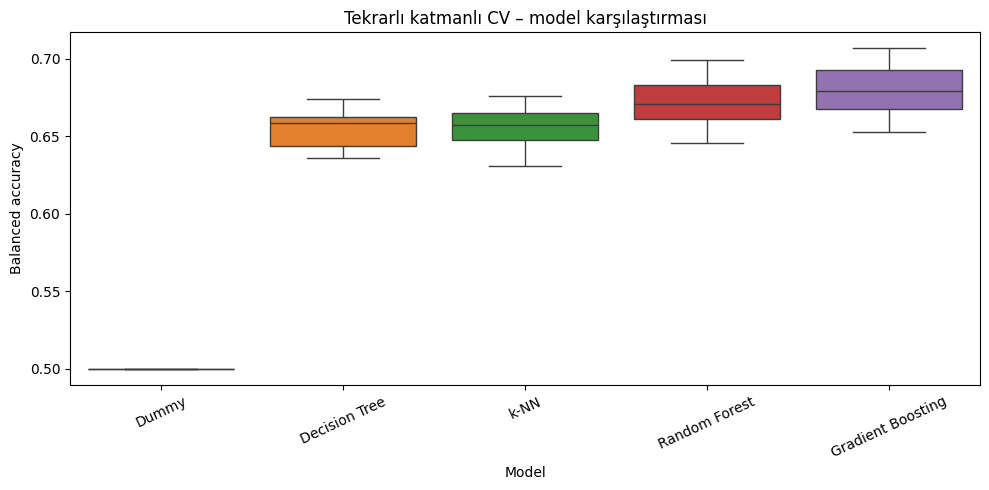

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


In [ ]:
plt.figure(figsize=(10,5))
sns.boxplot(data=pd.DataFrame(model_scores))
plt.ylabel("Balanced accuracy")
plt.xlabel("Model")
plt.title("Tekrarlı katmanlı CV – model karşılaştırması")
plt.xticks(rotation=25); plt.tight_layout()

## 10. Karar ağacı yorumu

In [ ]:
tree_pipe = Pipeline([("prep", make_preprocessor("onehot")),
                      ("model", DecisionTreeClassifier(max_depth=4, min_samples_leaf=20,
                                                        random_state=SEED, class_weight="balanced"))])
tree_pipe.fit(X_train, y_train)
feature_names = tree_pipe.named_steps["prep"].get_feature_names_out()
print(export_text(tree_pipe.named_steps["model"], feature_names=list(feature_names), max_depth=3))

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

|--- num__priors_count <= -0.37
|   |--- num__age <= -1.03
|   |   |--- num__age <= -1.20
|   |   |   |--- num__priors_count <= -0.58
|   |   |   |   |--- class: 1
|   |   |   |--- num__priors_count >  -0.58
|   |   |   |   |--- class: 1
|   |   |--- num__age >  -1.20
|   |   |   |--- num__juv_other_count <= 0.79
|   |   |   |   |--- class: 1
|   |   |   |--- num__juv_other_count >  0.79
|   |   |   |   |--- class: 1
|   |--- num__age >  -1.03
|   |   |--- num__age <= 0.07
|   |   |   |--- num__priors_count <= -0.58
|   |   |   |   |--- class: 0
|   |   |   |--- num__priors_count >  -0.58
|   |   |   |   |--- class: 0
|   |   |--- num__age >  0.07
|   |   |   |--- num__priors_count <= -0.58
|   |   |   |   |--- class: 0
|   |   |   |--- num__priors_count >  -0.58
|   |   |   |   |--- class: 0
|--- num__priors_count >  -0.37
|   |--- num__age <= -0.18
|   |   |--- num__priors_count <= 0.67
|   |   |   |--- num__age <= -1.20
|   |   |   |   |--- class: 1
|   |   |   |--- num__age >  -1.2

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

## 11. Optimist yanlılık ve iç içe çapraz doğrulama

In [ ]:
search_pipe = Pipeline([("prep", make_preprocessor("onehot")),
                        ("model", LogisticRegression(max_iter=3000, class_weight="balanced"))])
param_grid = {"model__C":[0.01, 0.1, 1, 10]}
inner = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
outer = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED+1)
gs = GridSearchCV(search_pipe, param_grid, cv=inner, scoring="balanced_accuracy", n_jobs=-1)
gs.fit(X_train, y_train)
nested = cross_val_score(GridSearchCV(search_pipe, param_grid, cv=inner,
    scoring="balanced_accuracy", n_jobs=-1), X_train, y_train,
    cv=outer, scoring="balanced_accuracy", n_jobs=-1)
print("GridSearchCV best_score_ (iyimser iç skor):", gs.best_score_)
print("Nested CV:", nested.mean(), "±", nested.std())
print("Seçilen parametre:", gs.best_params_)

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

GridSearchCV best_score_ (iyimser iç skor): 0.6748532247069766
Nested CV: 0.6733034555655829 ± 0.012584500231033673
Seçilen parametre: {'model__C': 0.01}


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

## 12. Holdout değerlendirmesi ve McNemar testi

In [ ]:
# Önce CV tablosuna göre en iyi iki modelin isimlerini doğrulayın; burada örnek olarak RF ve GB.
candidate_names = ["Random Forest", "Gradient Boosting"]
fitted = {}
for name in candidate_names:
    est = Pipeline([("prep", make_preprocessor("onehot")), ("model", models[name])])
    est.fit(X_train, y_train)
    fitted[name] = est
    pred = est.predict(X_test)
    print("\n", name)
    print(classification_report(y_test, pred, zero_division=0))
    print("Balanced accuracy:", balanced_accuracy_score(y_test, pred))

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag


 Random Forest
              precision    recall  f1-score   support

           0       0.69      0.72      0.70       673
           1       0.64      0.61      0.63       562

    accuracy                           0.67      1235
   macro avg       0.67      0.67      0.67      1235
weighted avg       0.67      0.67      0.67      1235

Balanced accuracy: 0.6650375701300281


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag


 Gradient Boosting
              precision    recall  f1-score   support

           0       0.69      0.76      0.72       673
           1       0.67      0.59      0.63       562

    accuracy                           0.68      1235
   macro avg       0.68      0.68      0.68      1235
weighted avg       0.68      0.68      0.68      1235

Balanced accuracy: 0.6753105286257423


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

In [ ]:
# McNemar: aynı test gözlemlerindeki iki modelin doğru/yanlış durumları karşılaştırılır.
p1 = fitted[candidate_names[0]].predict(X_test)
p2 = fitted[candidate_names[1]].predict(X_test)
c1 = (p1 == y_test.to_numpy()); c2 = (p2 == y_test.to_numpy())
table = [[np.sum(c1 & c2), np.sum(c1 & ~c2)],
         [np.sum(~c1 & c2), np.sum(~c1 & ~c2)]]
print("McNemar 2x2 tablo:", table)
print(mcnemar(table, exact=False, correction=True))

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

McNemar 2x2 tablo: [[np.int64(775), np.int64(52)], [np.int64(68), np.int64(340)]]
pvalue      0.17090352023079358
statistic   1.875


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

## 13. COMPAS skorunun ayrı denetimi
COMPAS puanı 1–10 aralığındadır. ProPublica'nın yaygın ikili analizinde 1–4 düşük; 5–10 orta/yüksek risk olarak ele alınır. Bu eşik model eğitiminden bağımsızdır ve açıkça raporlanmalıdır.

In [ ]:
audit = analysis.loc[X_test.index].copy()
audit["compas_high"] = (audit["decile_score"] >= 5).astype(int)
audit["y_true"] = y_test
def group_error_table(data, group_col, pred_col):
    rows=[]
    for group, part in data.groupby(group_col, dropna=False):
        tn, fp, fn, tp = confusion_matrix(part["y_true"], part[pred_col], labels=[0,1]).ravel()
        rows.append({"group":group, "n":len(part), "FPR":fp/(fp+tn) if fp+tn else np.nan,
                     "FNR":fn/(fn+tp) if fn+tp else np.nan,
                     "TPR":tp/(tp+fn) if tp+fn else np.nan,
                     "selection_rate":part[pred_col].mean(),
                     "PPV":tp/(tp+fp) if tp+fp else np.nan})
    return pd.DataFrame(rows)
display(group_error_table(audit, "race", "compas_high"))
display(group_error_table(audit, "sex", "compas_high"))

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

,group,n,FPR,FNR,TPR,selection_rate,PPV
0,African-American,671,0.422018,0.281977,0.718023,0.573770,0.641558
1,Asian,7,0.000000,0.500000,0.500000,0.142857,1.000000
2,Caucasian,395,0.193966,0.503067,0.496933,0.318987,0.642857
3,Hispanic,93,0.179104,0.653846,0.346154,0.225806,0.428571
4,Other,69,0.095238,0.444444,0.555556,0.275362,0.789474


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


,group,n,FPR,FNR,TPR,selection_rate,PPV
0,Female,226,0.321429,0.290698,0.709302,0.469027,0.575472
1,Male,1009,0.288931,0.386555,0.613445,0.442022,0.654709


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

## 14. Weka ile bağımsız kontrol – zorunlu
Aşağıdaki CSV dosyası Weka Explorer'da açılacaktır. Weka'da `two_year_recid` sınıf değişkeni seçilir; ZeroR ve J48, 10-fold cross-validation ile çalıştırılır. Aynı filtrelenmiş kayıtlar ve aynı hedef kullanılmalıdır.

In [ ]:
weka_data = analysis[MODEL_COLS + [TARGET]].copy()
weka_data.to_csv("/content/compas_weka.csv", index=False)
print("Weka için dışa aktarıldı: /content/compas_weka.csv")

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

Weka için dışa aktarıldı: /content/compas_weka.csv


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

### Weka uygulama adımları
1. Weka Explorer → Preprocess → `compas_weka.csv` dosyasını açın.
2. Class alanını `two_year_recid` seçin.
3. Classify → Choose → `ZeroR` → Test options: Cross-validation, Folds=10 → Start.
4. Aynı işlemi `trees → J48` ile tekrarlayın.
5. Weka çıktısındaki doğru sınıflandırma oranı, confusion matrix, precision/recall ve kappa değerlerini kaydedin.
6. Python'da aynı 10-fold bölme/ölçütleri kullanarak karşılaştırın. Weka ekran görüntülerini teslim klasörünüzde saklayın.

**Not:** Weka'nın ZeroR/J48 sonuçları Python'daki aynı algoritmalarla birebir aynı olmak zorunda değildir; sürüm, varsayılan ayarlar ve bölme tohumu farklarını raporlayın.

## 15. Veri küpü – roll-up, drill-down ve Simpson paradoksu

In [ ]:
cube = analysis.groupby(["race", "sex", "age_cat"], dropna=False).agg(
    n=("two_year_recid","size"), recid_rate=("two_year_recid","mean"),
    mean_compas_score=("decile_score","mean")).reset_index()
display(cube.head(20))
rollup = analysis.groupby(["race","sex"], dropna=False).agg(
    n=("two_year_recid","size"), recid_rate=("two_year_recid","mean")).reset_index()
display(rollup)
drilldown = analysis.groupby(["race","sex","age_cat"], dropna=False)["two_year_recid"].agg(
    ["count","mean"]).reset_index()
display(drilldown)

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

,race,sex,age_cat,n,recid_rate,mean_compas_score
0,African-American,Female,25 - 45,335,0.367164,4.444776
1,African-American,Female,Greater than 45,69,0.231884,3.000000
2,African-American,Female,Less than 25,145,0.441379,5.868966
3,African-American,Male,25 - 45,1563,0.547025,5.433781
4,African-American,Male,Greater than 45,399,0.441103,3.982456
5,African-American,Male,Less than 25,664,0.643072,6.212349
6,Asian,Female,25 - 45,1,0.000000,1.000000
7,Asian,Female,Greater than 45,1,1.000000,3.000000
8,Asian,Male,25 - 45,13,0.153846,2.846154
9,Asian,Male,Greater than 45,10,0.300000,2.100000


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


,race,sex,n,recid_rate
0,African-American,Female,549,0.369763
1,African-American,Male,2626,0.555217
2,Asian,Female,2,0.500000
3,Asian,Male,29,0.241379
4,Caucasian,Female,482,0.352697
5,Caucasian,Male,1621,0.402221
6,Hispanic,Female,82,0.317073
7,Hispanic,Male,427,0.381733
8,Native American,Female,2,1.000000
9,Native American,Male,9,0.333333


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

,race,sex,age_cat,count,mean
0,African-American,Female,25 - 45,335,0.367164
1,African-American,Female,Greater than 45,69,0.231884
2,African-American,Female,Less than 25,145,0.441379
3,African-American,Male,25 - 45,1563,0.547025
4,African-American,Male,Greater than 45,399,0.441103
5,African-American,Male,Less than 25,664,0.643072
6,Asian,Female,25 - 45,1,0.000000
7,Asian,Female,Greater than 45,1,1.000000
8,Asian,Male,25 - 45,13,0.153846
9,Asian,Male,Greater than 45,10,0.300000


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

## 16. Birliktelik analizi – Seçenek B
Her satır bir kişi olduğu için işlem bilgisi yoktur. Sayısal değişkenler gerekçeli aralıklara ayrılır; her kişi `özellik=değer` öğelerinden oluşan bir işlem olarak temsil edilir. Bu analiz betimseldir; nedensellik göstermez.

In [ ]:
basket = analysis[["age","priors_count","juv_fel_count","c_charge_degree","race","two_year_recid"]].copy()
basket["age_bin"] = pd.cut(basket["age"], bins=[0,25,35,45,100],
                           labels=["18-24","25-34","35-44","45+"])
basket["priors_bin"] = pd.cut(basket["priors_count"], bins=[-1,0,2,5,100],
                              labels=["0","1-2","3-5","6+"])
transactions = []
for _, row in basket.iterrows():
    transactions.append([
        f"age={row['age_bin']}", f"priors={row['priors_bin']}",
        f"charge={row['c_charge_degree']}", f"race={row['race']}",
        f"target={int(row['two_year_recid'])}"
    ])
te = TransactionEncoder()
arr = te.fit(transactions).transform(transactions)
basket_ohe = pd.DataFrame(arr, columns=te.columns_)
print("İşlem matrisi:", basket_ohe.shape)

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

İşlem matrisi: (6172, 18)


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

In [ ]:
bench=[]
for support in [0.03, 0.05, 0.08]:
    for name, fn in [("Apriori", apriori), ("FP-Growth", fpgrowth)]:
        start=time.perf_counter()
        freq=fn(basket_ohe, min_support=support, use_colnames=True)
        elapsed=time.perf_counter()-start
        bench.append({"algorithm":name,"min_support":support,
                      "patterns":len(freq),"seconds":elapsed})
display(pd.DataFrame(bench))

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

,algorithm,min_support,patterns,seconds
0,Apriori,0.03,261,0.039867
1,FP-Growth,0.03,261,0.096765
2,Apriori,0.05,157,0.019460
3,FP-Growth,0.05,157,0.116849
4,Apriori,0.08,94,0.014136
5,FP-Growth,0.08,94,0.093141


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

In [ ]:
freq = fpgrowth(basket_ohe, min_support=0.03, use_colnames=True)
rules = association_rules(freq, metric="confidence", min_threshold=0.20)
# Hedefi sonuç tarafında içeren kurallar
rules = rules[rules["consequents"].apply(lambda s: any(str(x).startswith("target=") for x in s))].copy()
def kulczynski(row):
    # Kulc(A,B) = [P(B|A) + P(A|B)] / 2
    conf_ab = row["confidence"]
    conf_ba = row["support"] / row["consequent support"]
    return (conf_ab + conf_ba)/2
rules["kulczynski"] = rules.apply(kulczynski, axis=1)
rules["imbalance_ratio"] = (rules["antecedent support"]-rules["consequent support"]).abs() / (
    rules["antecedent support"]+rules["consequent support"]-rules["support"])
display(rules.sort_values("lift", ascending=False)[
    ["antecedents","consequents","support","confidence","lift","kulczynski","imbalance_ratio"]].head(10))

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

,antecedents,consequents,support,confidence,lift,kulczynski,imbalance_ratio
781,frozenset({priors=6+}),"frozenset({target=1, age=25-34, charge=F, race...",0.045042,0.227682,2.744638,0.385325,0.487285
779,"frozenset({charge=F, priors=6+})","frozenset({target=1, age=25-34, race=African-A...",0.045042,0.296060,2.617880,0.347170,0.177336
749,frozenset({priors=6+}),"frozenset({age=25-34, race=African-American, t...",0.057518,0.290745,2.570888,0.399671,0.334399
780,"frozenset({race=African-American, priors=6+})","frozenset({target=1, age=25-34, charge=F})",0.045042,0.320276,2.508562,0.336534,0.058055
778,"frozenset({age=25-34, priors=6+})","frozenset({target=1, charge=F, race=African-Am...",0.045042,0.485166,2.460512,0.356798,0.425926
158,"frozenset({age=45+, priors=0})","frozenset({target=0, race=Caucasian})",0.033539,0.498795,2.403250,0.330194,0.581598
774,"frozenset({charge=F, race=African-American, pr...","frozenset({target=1, age=25-34})",0.045042,0.419940,2.343460,0.335648,0.297987
745,"frozenset({age=25-34, priors=6+})","frozenset({target=1, race=African-American})",0.057518,0.619546,2.302131,0.416636,0.579031
772,"frozenset({age=25-34, charge=F, priors=6+})","frozenset({target=1, race=African-American})",0.045042,0.619154,2.300672,0.393261,0.661572
747,"frozenset({race=African-American, priors=6+})","frozenset({age=25-34, target=1})",0.057518,0.408986,2.282335,0.364981,0.147004


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

### Null-invariance deneyi ve kural yorumu
200 ilgisiz nadir öğe ekleyin; destek eşiği, kural sıralaması ve Kulczynski/imbalance oranının nasıl etkilendiğini gözleyin. En az üç kuralı alan bilgisiyle yorumlayın. Nadir gruplarda lift'in yüksek çıkmasının tek başına güçlü ilişki kanıtı olmadığını tartışın. Null-invariance deneyinde rastgele öğe üretim tohumunu sabitleyin.

In [ ]:
# Basit null-invariance deneyi: 200 nadir ve bağımsız gürültü öğesi ekle.
rng=np.random.default_rng(SEED)
noise = pd.DataFrame({f"noise_{i}": (rng.random(len(basket_ohe)) < 0.005)
                      for i in range(200)})
basket_noise = pd.concat([basket_ohe.reset_index(drop=True), noise], axis=1)
freq_noise = fpgrowth(basket_noise, min_support=0.03, use_colnames=True)
print("Özgün örüntü sayısı:", len(freq), "| Gürültü eklenmiş örüntü sayısı:", len(freq_noise))

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

Özgün örüntü sayısı: 261 | Gürültü eklenmiş örüntü sayısı: 261


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

## 17. Proje 2'ye aktarılacak çıktılar

In [46]:
# Son model: CV sonuçlarını ve bilimsel gerekçeyi dikkate alarak burada seçin.
# Örnek seçim aşağıdaki satırda güncellenmelidir.
selected_name = "Gradient Boosting"
selected_model = Pipeline([("prep", make_preprocessor("onehot")), ("model", models[selected_name])])
selected_model.fit(X, y)
clean_export = analysis.copy()
clean_export.to_csv("/content/compas_project1_clean.csv", index=False)
import joblib
joblib.dump(selected_model, "/content/compas_project1_best_model.joblib")
metadata = {
    "student":"Murat Sağlam", "student_no":"264327008", "topic":"9.16 COMPAS",
    "target":"two_year_recid", "features":MODEL_COLS, "protected_attributes":PROTECTED,
    "selected_model":selected_name, "seed":SEED,
    "warning":"two_year_recid is a proxy for rearrest, not crime commission."
}
with open("/content/compas_project1_metadata.json","w",encoding="utf-8") as f:
    json.dump(metadata,f,ensure_ascii=False,indent=2)
print("Proje 2 aktarım dosyaları hazırlandı.")

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

Proje 2 aktarım dosyaları hazırlandı.


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

## 18. Varsayım defteri
Aşağıdaki kararları gerçek çalışmanızla uyumlu şekilde tamamlayın:
- Hedefin yeniden tutuklanma vekili olarak ele alınması.
- 30 günlük eşleştirme filtresi, `is_recid != -1`, `c_charge_degree != O`, `score_text != N/A` filtreleri.
- Kişisel tanımlayıcıların ve sonradan oluşan alanların dışlanması.
- Irk ve cinsiyetin model girdisi değil, adillik denetimi için korunması.
- `decile_score` / `score_text` alanlarının yeni sınıflandırıcıdan ayrı denetlenmesi.
- Sınıf dengesizliği nedeniyle balanced accuracy, F1 ve ROC-AUC raporlanması.
- CV ve ön işleme kararlarının gerekçesi.
- Veri lisansının teyit edilmesi.

## 19. Katkı beyanı
**Murat Sağlam (264327008):** Veri edinme ve temizleme, EDA, ön işleme ve sızıntı deneyi, sınıflandırma, veri küpü ve birliktelik analizi, Weka doğrulaması, yorumlama ve sunum hazırlığı.  
**GitHub kanıtı:** Kendi commit geçmişinizle tutarlı olacak şekilde alt başlıkları ve gerçek katkı paylarını güncelleyin.

## 20. Yapay zekâ kullanım beyanı
Bu çalışma hazırlanırken ChatGPT, proje yönergesinin çözümlenmesi, analiz akışının planlanması, kod iskeletlerinin hazırlanması ve hata ayıklama desteği amacıyla kullanılmıştır. Veri sonuçları çalıştırılarak doğrulanmalı; yorumlar öğrenci tarafından kontrol edilmeli ve nihai sorumluluk öğrenciye aittir. Kullanım beyanı gerçek kullanımınıza göre güncellenmelidir.

## 21. Kaynaklar
1. Larson, J., Mattu, S., Kirchner, L., & Angwin, J. (2016). *How We Analyzed the COMPAS Recidivism Algorithm*. ProPublica. https://www.propublica.org/article/how-we-analyzed-the-compas-recidivism-algorithm
2. ProPublica. *compas-analysis: Data and analysis for “Machine Bias”*. https://github.com/propublica/compas-analysis
3. Kaufman, S., Rosset, S., Perlich, C., & Stitelman, O. (2012). Leakage in data mining: Formulation, detection, and avoidance. *ACM TKDD, 6*(4).
4. Dietterich, T. G. (1998). Approximate statistical tests for comparing supervised classification learning algorithms. *Neural Computation, 10*(7), 1895–1923.
5. Wu, T., Chen, Y., & Han, J. (2010). Re-examination of interestingness measures in pattern mining: A unified framework. *Data Mining and Knowledge Discovery, 21*(3), 371–397.
6. Bao, M. et al. (2021). It's COMPASlicated: The Messy Relationship between RAI Datasets and Algorithmic Fairness Benchmarks. *NeurIPS Datasets and Benchmarks*.

In [47]:
print("Seçilen model:", selected_name)
print("Metadata modeli:", metadata["selected_model"])

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

Seçilen model: Gradient Boosting
Metadata modeli: Gradient Boosting


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag